# Steel Surface Defect Classification using Deep Learning

This project explores deep learning techniques for classifying surface defects in hot-rolled steel using the NEU Surface Defect Database.

The dataset contains six types of steel surface defects:
- Crazing
- Inclusion
- Patches
- Pitted Surface
- Rolled-in Scale
- Scratches

The goal is to build and evaluate deep learning models for automatically classifying these defect types from grayscale images.

In [1]:
import kagglehub
from google.colab import drive
drive.mount("/content/drive")

path = kagglehub.dataset_download(
    "kaustubhdikshit/neu-surface-defect-database"
)

print("Dataset path:", path)

Mounted at /content/drive
Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Dataset path: /kaggle/input/neu-surface-defect-database


In [2]:
import os

print(os.listdir(path))

['NEU-DET']


In [3]:
dataset_path = os.path.join(path, "NEU-DET")

print(os.listdir(dataset_path))

['validation', 'train']


In [4]:
train_path = os.path.join(dataset_path, "train")

print(os.listdir(train_path))

['annotations', 'images']


In [5]:
images_path = os.path.join(train_path, "images")

class_names = os.listdir(images_path)

print("Number of classes:", len(class_names))
print("Classes:", class_names)

Number of classes: 6
Classes: ['inclusion', 'scratches', 'pitted_surface', 'patches', 'crazing', 'rolled-in_scale']


In [6]:
for clas in class_names:
  class_path = os.path.join(images_path, clas)
  print("Number of images of",clas, " :" ,len(os.listdir(class_path)))


Number of images of inclusion  : 240
Number of images of scratches  : 240
Number of images of pitted_surface  : 240
Number of images of patches  : 240
Number of images of crazing  : 240
Number of images of rolled-in_scale  : 240


In [7]:
validation_path = os.path.join(dataset_path,"validation")
print(os.listdir(validation_path))

['annotations', 'images']


In [8]:
val_images = os.path.join(validation_path,"images")
print(os.listdir(val_images))
for clas in os.listdir(val_images):
  clas_path= os.path.join(val_images,clas)
  print("number of images in",clas," :",len(os.listdir(clas_path)))

['inclusion', 'scratches', 'pitted_surface', 'patches', 'crazing', 'rolled-in_scale']
number of images in inclusion  : 60
number of images in scratches  : 60
number of images in pitted_surface  : 60
number of images in patches  : 60
number of images in crazing  : 60
number of images in rolled-in_scale  : 60


we can see that dataset is balanced as stated

In [9]:
crazing_path = os.path.join(images_path, "crazing")

crazing_files = os.listdir(crazing_path)

print(crazing_files[:5])

['crazing_1.jpg', 'crazing_45.jpg', 'crazing_199.jpg', 'crazing_80.jpg', 'crazing_113.jpg']


In [10]:
from PIL import Image
first_image_path = os.path.join(crazing_path, crazing_files[0])
print(first_image_path)
image = Image.open(first_image_path)
print("Image size:", image.size)
print("Image mode:", image.mode)

/kaggle/input/neu-surface-defect-database/NEU-DET/train/images/crazing/crazing_1.jpg
Image size: (200, 200)
Image mode: RGB


i will make the image a Numpy array

In [11]:
import numpy as np

image_array = np.array(image)

print("Shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Min pixel value:", image_array.min())
print("Max pixel value:", image_array.max())
print("First pixel:", image_array[0, 0])

Shape: (200, 200, 3)
Data type: uint8
Min pixel value: 60
Max pixel value: 255
First pixel: [185 185 185]


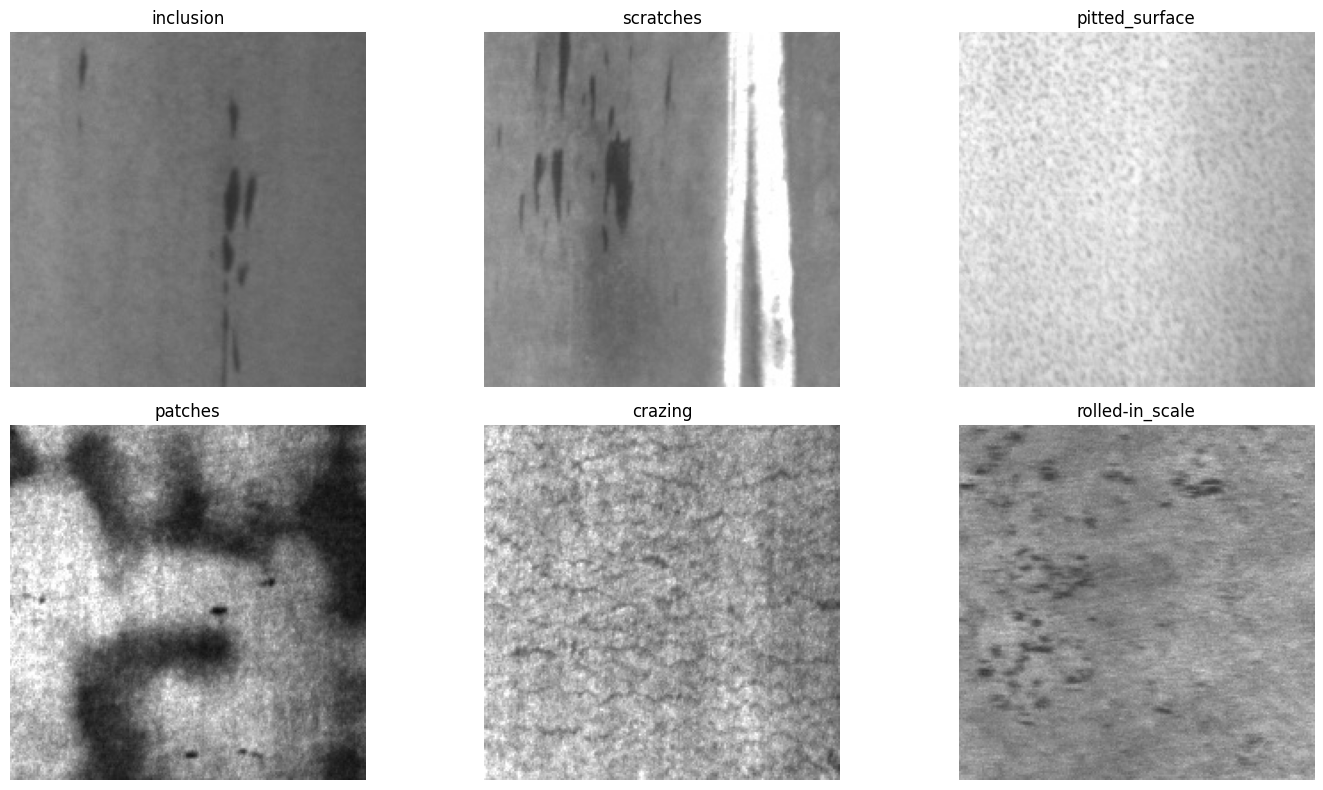

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))

for i, class_name in enumerate(class_names):
    class_path = os.path.join(images_path, class_name)
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path)

    plt.subplot(2, 3, i + 1) # מחלק את המשטח לרשת של 2 שורות ו-3 עמודות
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

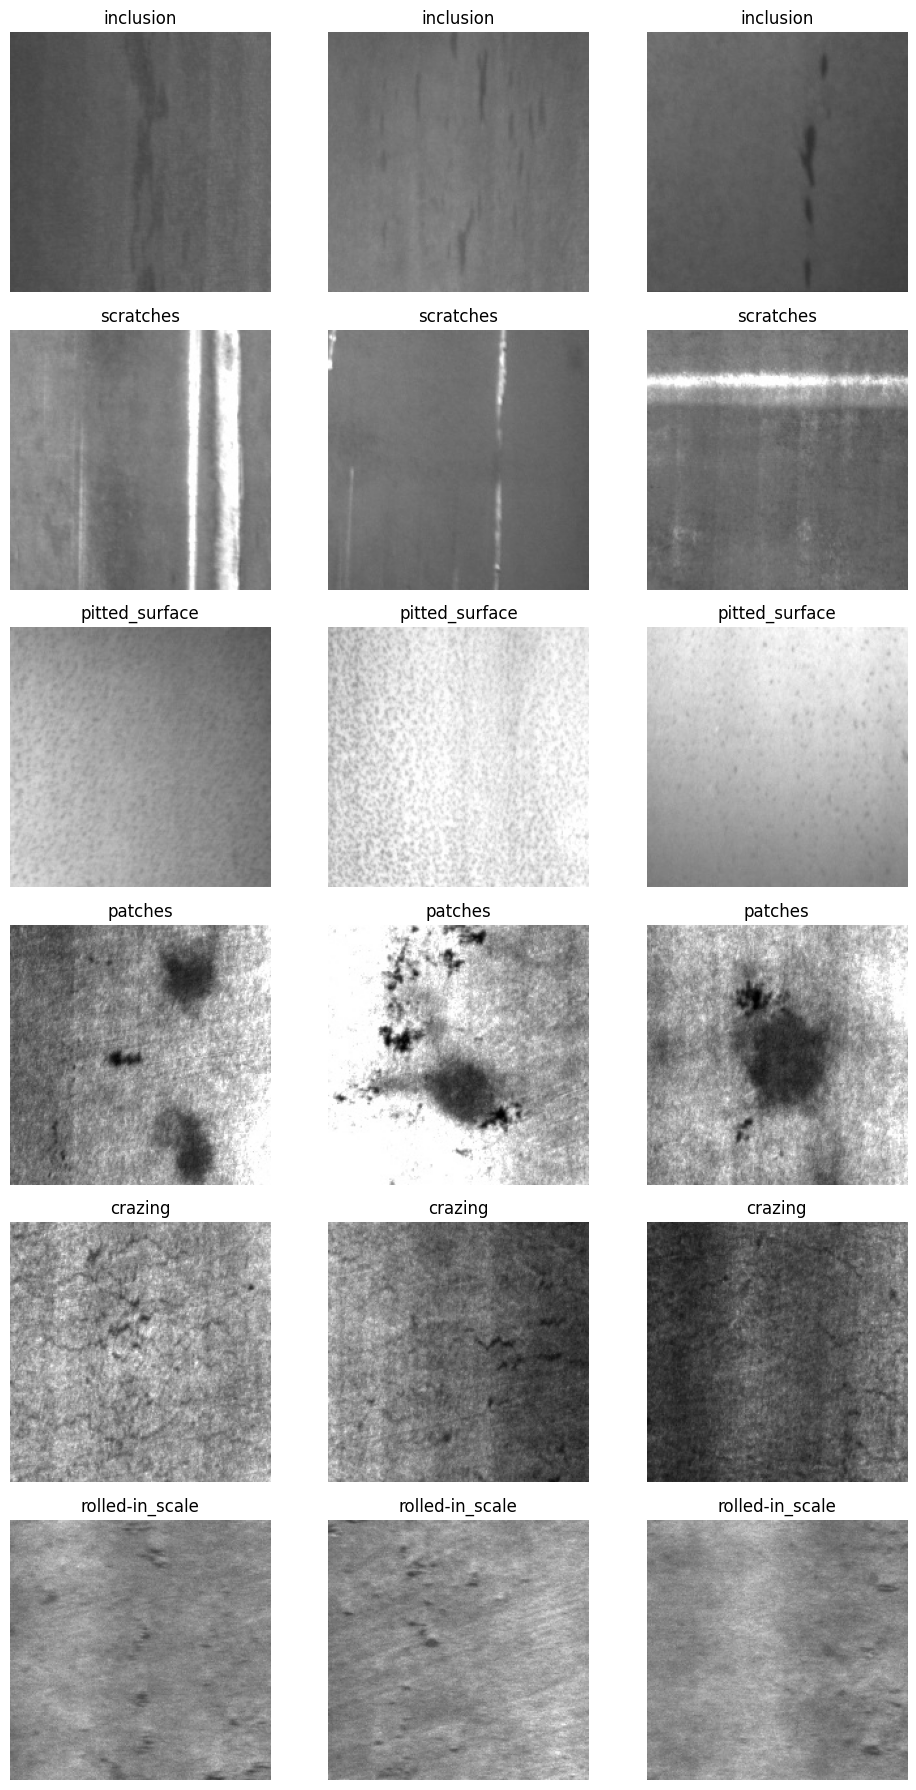

In [13]:
import matplotlib.pyplot as plt
import random

fig, axes = plt.subplots(6, 3, figsize=(10, 18))

for i, class_name in enumerate(class_names):
    class_path = os.path.join(images_path, class_name)
    selected_images = random.sample(os.listdir(class_path), 3)
    for j, img in enumerate(selected_images):
      image_path = os.path.join(class_path, img)
      image = Image.open(image_path)
      axes[i, j].imshow(image)
      axes[i, j].set_title(class_name)
      axes[i, j].axis("off")
plt.tight_layout()
plt.show()


## Train / Validation / Test

i split only inculsion to see it how it works

In [14]:
inclusion_val_path = os.path.join(
    val_images,
    "inclusion"
)

files = os.listdir(inclusion_val_path)
random.seed(42)
random.shuffle(files)
validation_files = files[:30]
test_files = files[30:]
print(len(files))
print(len(validation_files))
print(len(test_files))

60
30
30


In [15]:
validation_data = []
test_data = []
random.seed(42)

for class_name in class_names:
    class_path = os.path.join(val_images, class_name)

    files = os.listdir(class_path)

    random.shuffle(files)

    validation_files = files[:30]
    test_files = files[30:]
    for val in validation_files:
      validation_data.append((os.path.join(class_path, val),class_name))
    for test in test_files:
      test_data.append((os.path.join(class_path, test),class_name))
print(len(validation_data))
print(len(test_data))

180
180


In [16]:
print(validation_data[:3])
print(test_data[:3])

[('/kaggle/input/neu-surface-defect-database/NEU-DET/validation/images/inclusion/inclusion_269.jpg', 'inclusion'), ('/kaggle/input/neu-surface-defect-database/NEU-DET/validation/images/inclusion/inclusion_272.jpg', 'inclusion'), ('/kaggle/input/neu-surface-defect-database/NEU-DET/validation/images/inclusion/inclusion_300.jpg', 'inclusion')]
[('/kaggle/input/neu-surface-defect-database/NEU-DET/validation/images/inclusion/inclusion_281.jpg', 'inclusion'), ('/kaggle/input/neu-surface-defect-database/NEU-DET/validation/images/inclusion/inclusion_277.jpg', 'inclusion'), ('/kaggle/input/neu-surface-defect-database/NEU-DET/validation/images/inclusion/inclusion_297.jpg', 'inclusion')]


In [17]:
from collections import Counter

print(Counter(label for path, label in validation_data))
print(Counter(label for path, label in test_data))

Counter({'inclusion': 30, 'scratches': 30, 'pitted_surface': 30, 'patches': 30, 'crazing': 30, 'rolled-in_scale': 30})
Counter({'inclusion': 30, 'scratches': 30, 'pitted_surface': 30, 'patches': 30, 'crazing': 30, 'rolled-in_scale': 30})


In [18]:
validation_paths = set(path for path, label in validation_data)
test_paths = set(path for path, label in test_data)

print(len(validation_paths & test_paths))

0


no duplicate was found so we can continue

## Data Pipeline
make jpg to data CNN can get

In [19]:
import tensorflow as tf

print(tf.__version__)

2.21.0


In [20]:
IMG_HEIGHT = 200
IMG_WIDTH = 200
BATCH_SIZE = 32

In [21]:
class_to_index = {}
for index, class_name in enumerate(class_names):
    class_to_index[class_name] = index
print(class_to_index)

{'inclusion': 0, 'scratches': 1, 'pitted_surface': 2, 'patches': 3, 'crazing': 4, 'rolled-in_scale': 5}


In [22]:
image_path, label = validation_data[0]

print(image_path)
print(label)
image = tf.io.read_file(image_path)
image = tf.image.decode_jpeg(image, channels=3)

print(image.shape)
print(image.dtype)

/kaggle/input/neu-surface-defect-database/NEU-DET/validation/images/inclusion/inclusion_269.jpg
inclusion
(200, 200, 3)
<dtype: 'uint8'>


there is an important detail: image is currently of type uint8. We need floating-point numbers, so we will first convert it to float32

In [23]:
image = tf.cast(image, tf.float32)
image = image / 255.0

print(image.dtype)
print(tf.reduce_min(image).numpy()) # מוצא את ערך הפיקסל הנמוך ביותר בתמונה וממיר אותו למספר פייתון רגיל
print(tf.reduce_max(image).numpy()) # מוצא את ערך הפיקסל הגבוה ביותר

<dtype: 'float32'>
0.101960786
0.28627452


In [24]:
def load_and_preprocess_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3) # 2. decode JPEG with 3 channels
    image = tf.image.resize(image, [IMG_HEIGHT, IMG_WIDTH])
    image = tf.cast(image, tf.float32) # 3. convert to float32
    image = image / 255.0 # 4. normalize to 0-1
    return image

Test my Function works

In [25]:
image_path, label = validation_data[0]

processed_image = load_and_preprocess_image(image_path)

print("Shape:", processed_image.shape)
print("Type:", processed_image.dtype)
print("Min:", tf.reduce_min(processed_image).numpy())
print("Max:", tf.reduce_max(processed_image).numpy())

Shape: (200, 200, 3)
Type: <dtype: 'float32'>
Min: 0.101960786
Max: 0.28627452


In [26]:
val_paths = []
val_labels = []

for path, label in validation_data:
    val_paths.append(path)
    val_labels.append(class_to_index[label])
print(len(val_paths))
print(len(val_labels))
print(val_paths[0])
print(val_labels[0])

180
180
/kaggle/input/neu-surface-defect-database/NEU-DET/validation/images/inclusion/inclusion_269.jpg
0


converting to tesnor dataset

In [27]:
val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)  # מצמידה אותם לפי האינדקס

In [28]:
def preprocess(path, label):
    image = load_and_preprocess_image(path)
    return image, label

In [29]:
val_dataset = val_dataset.map(preprocess) # runs preprocesss on every pair in dataset

In [30]:
for image, label in val_dataset.take(1):
    print("Image shape:", image.shape)
    print("Image dtype:", image.dtype)
    print("Label:", label.numpy())

Image shape: (200, 200, 3)
Image dtype: <dtype: 'float32'>
Label: 0


batching

In [31]:
val_dataset = val_dataset.batch(BATCH_SIZE) # מחלק את הנתונים לקבוצות בגודל שנתנו

In [32]:
for images, labels in val_dataset.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Labels:", labels.numpy())

Images shape: (32, 200, 200, 3)
Labels shape: (32,)
Labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1]


In [33]:
print("Number of batches:", len(val_dataset))

for images, labels in val_dataset:
    print(images.shape)

Number of batches: 6
(32, 200, 200, 3)
(32, 200, 200, 3)
(32, 200, 200, 3)
(32, 200, 200, 3)
(32, 200, 200, 3)
(20, 200, 200, 3)


building train dataset

In [34]:
train_paths = []
train_labels = []
for class_name in class_names:
    class_path = os.path.join(images_path, class_name)

    for filename in os.listdir(class_path):
        train_paths.append(os.path.join(class_path,filename))
        train_labels.append(class_to_index[class_name])
print(len(train_paths))
print(len(train_labels))
print(train_paths[0])
print(train_labels[0])

1440
1440
/kaggle/input/neu-surface-defect-database/NEU-DET/train/images/inclusion/inclusion_1.jpg
0


In [35]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)
train_dataset = train_dataset.shuffle(
    buffer_size=len(train_paths),
    seed=42
)

In [36]:
train_dataset = train_dataset.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE # Allows TensorFlow to process multiple images in parallel and select the appropriate level of parallelism.
)

train_dataset = train_dataset.batch(BATCH_SIZE)
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)  #Allows additional batches to be prepared while the model works on the current batch, reducing idle time spent waiting for data loading

check it worked

In [37]:
print("Number of batches:", len(train_dataset))

for images, labels in train_dataset.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Labels:", labels.numpy())

Number of batches: 45
Images shape: (32, 200, 200, 3)
Labels shape: (32,)
Labels: [0 3 0 3 1 1 3 2 4 5 5 2 4 3 2 5 4 3 2 5 0 2 1 0 5 4 3 2 0 2 3 0]


test dataset

In [38]:
# Extract image paths and numeric labels
test_paths = [path for path, label in test_data]
test_labels = [class_to_index[label] for path, label in test_data]

# Create TensorFlow Dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

# Preprocess images
test_dataset = test_dataset.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Create batches
test_dataset = test_dataset.batch(BATCH_SIZE)

# Optimize data loading
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

# Verify
print("Number of batches:", len(test_dataset))

for images, labels in test_dataset.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

Number of batches: 6
Images shape: (32, 200, 200, 3)
Labels shape: (32,)


In [39]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(200, 200, 3)),
    layers.Conv2D(
        filters=16, # learns 16 Feature Maps compunational price not that high
        kernel_size=(3, 3),
        activation="relu", # most of the times better than sigmoid
        padding="same" #שומר על הגובה והרוחב של התמונה כאשר strides=1
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 200, 200, 16)   │           448 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 448 (1.75 KB)

 Trainable params: 448 (1.75 KB)

 Non-trainable params: 0 (0.00 B)

Trainable params: All 448 parameters can be updated during training via backpropagation and the optimizer.

Non-trainable params: Parameters that are not updated during training. Currently, there are none.

Conv2D detects patterns in the image and generates feature maps.

MaxPooling2D reduces the height and width of the feature maps, while retaining the highest values in each region.

In [40]:
model = keras.Sequential([
    layers.Input(shape=(200, 200, 3)),

    layers.Conv2D(
        filters=16,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(pool_size=(2, 2))
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 200, 200, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 16)   │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 448 (1.75 KB)

 Trainable params: 448 (1.75 KB)

 Non-trainable params: 0 (0.00 B)

The number of channels remains 16. Pooling reduces only the height and width, not the number of feature maps.

The MaxPooling layer has no trainable parameters. It simply performs a fixed maximum operation. It contains no weights or biases that need to be trained.

In [41]:
model = keras.Sequential([
    layers.Input(shape=(200, 200, 3)),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)), # gradually reduce the spatial dimensions, so that subsequent layers operate on less data.

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),

    layers.Dense(6, activation="softmax")
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 200, 200, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 100, 100, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 100, 100, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,590 (29.65 KB)

 Trainable params: 7,590 (29.65 KB)

 Non-trainable params: 0 (0.00 B)

GlobalAveragePooling2D does something different: it calculates the average of each of the 32 feature maps.

In [42]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

#training first model

In [ ]:
checkpoint = keras.callbacks.ModelCheckpoint(
    filepath="/content/drive/MyDrive/steel_defect_best.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    callbacks=[checkpoint]
)

Epoch 1/10


KeyboardInterrupt: 

concise summary of the training:
Training Accuracy: Steady upward trend, improving from 19.65% in Epoch 1 to 71.88% in Epoch 10.

Validation Performance: Generalization accuracy climbed from 17.78% to 69.44% (peaking at 70.00% in Epoch 9).

Loss Convergence: Both training loss (
1.77→0.79
) and validation loss (
1.75→0.94
) decreased monotonically, indicating steady and healthy optimization.

Overfitting Status: There are no signs of overfitting yet. Because val_loss is still actively dropping, the model has not plateaued and would likely benefit from training for another 5–10 epochs.

Fluctuation Note: Epochs 7 and 8 showed a temporary dip in validation accuracy (down to 42.78%) before rebounding sharply in Epoch 9, which often points to a slightly aggressive learning rate or variance across small batch sizes.

In [43]:
model = keras.models.load_model(
    "/content/drive/MyDrive/steel_defect_best.keras"
)

In [ ]:
checkpoint = keras.callbacks.ModelCheckpoint(
    filepath="/content/drive/MyDrive/steel_defect_continued.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

history_continued = model.fit(
    train_dataset,
    validation_data=val_dataset,
    initial_epoch=10,
    epochs=20,
    callbacks=[checkpoint]
)

Epoch 11/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 120ms/step - accuracy: 0.7396 - loss: 0.7488 - val_accuracy: 0.7111 - val_loss: 0.8824
Epoch 12/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7333 - loss: 0.7213 - val_accuracy: 0.6056 - val_loss: 0.8185
Epoch 13/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.7556 - loss: 0.6717 - val_accuracy: 0.6556 - val_loss: 0.8201
Epoch 14/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.7688 - loss: 0.6502 - val_accuracy: 0.7333 - val_loss: 0.8260
Epoch 15/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.7576 - loss: 0.6357 - val_accuracy: 0.7333 - val_loss: 0.8087
Epoch 16/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7472 - loss: 0.6662 - val_accuracy: 0.5389 - val_loss: 0.8435
Epoch 17/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7521 - loss: 0.6292 - val_accuracy: 0.7778 - val_loss: 0.7223
Epoch 18/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7896 - loss: 0.5717 - val_accuracy: 0

6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 189ms/step
                 precision    recall  f1-score   support

      inclusion       0.94      0.53      0.68        30
      scratches       0.64      0.93      0.76        30
 pitted_surface       0.70      0.63      0.67        30
        patches       0.73      0.80      0.76        30
        crazing       0.78      0.70      0.74        30
rolled-in_scale       0.94      1.00      0.97        30

       accuracy                           0.77       180
      macro avg       0.79      0.77      0.76       180
   weighted avg       0.79      0.77      0.76       180



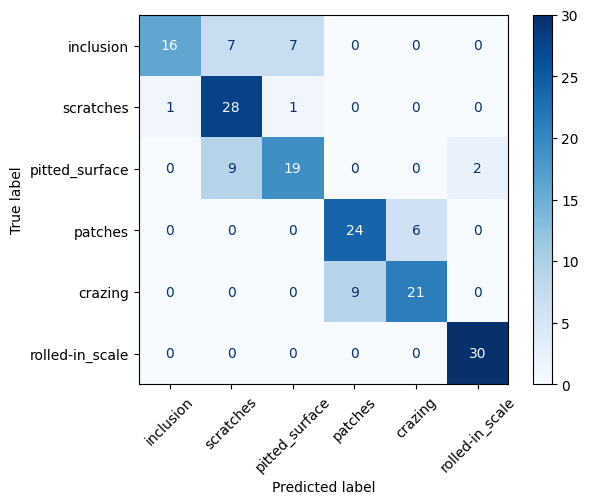

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Load the best model from the continued training
best_model = keras.models.load_model(
    "/content/drive/MyDrive/steel_defect_continued.keras"
)

# Predictions on validation data
val_probabilities = best_model.predict(val_dataset)
y_pred = np.argmax(val_probabilities, axis=1)

# True labels
y_true = np.concatenate([
    labels.numpy() for images, labels in val_dataset
])

# Metrics per class
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues"
)

plt.show()

## First Model Evaluation & Error Analysis
### 1. Overall Performance
* **Validation Accuracy:** **76.67%** (138 / 180 images correctly classified).
* **Summary:** A solid baseline performance for a lightweight custom CNN trained from scratch, though error rates vary significantly across defect categories.
#### Key Observations:
* **Best Class (`rolled-in_scale`):**
  * Flawless recall (100% — 30/30 detected) with high precision (94% — only 2 false positives out of 32 predictions).
  * Indicates the CNN learned highly discriminative visual features for this defect.
* **Most Problematic Class (`inclusion`):**
  * Shows high precision (94%) but critically low recall (53%).
  * The model is overly conservative: when it predicts `inclusion`, it is almost always correct (16/17), but it misses 14 out of 30 actual cases (7 misclassified as `scratches`, 7 as `pitted_surface`).

---

### 3. Confusion Matrix Patterns

Errors are systematically clustered rather than randomly distributed:

1. **Cluster 1: Linear & Point Defects (`inclusion`, `scratches`, `pitted_surface`)**
   * `scratches` has high recall (93%) but low precision (64%), acting as a "sink" for false positives.
   * `pitted_surface` loses 9 images to `scratches`.
   * `inclusion` is split evenly between `scratches` (7) and `pitted_surface` (7).

2. **Cluster 2: Surface Texture Defects (`patches` $\leftrightarrow$ `crazing`)**
   * Bidirectional confusion: 6 `patches` misclassified as `crazing`, and 9 `crazing` misclassified as `patches`.

---

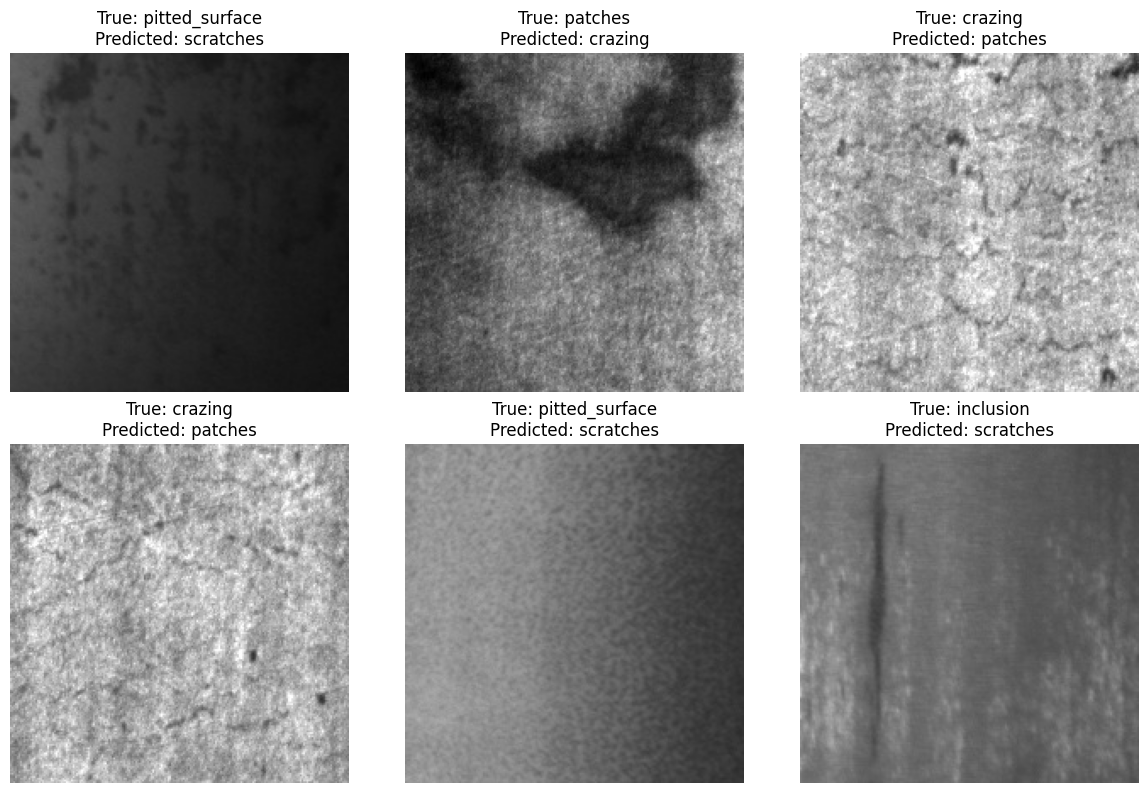

In [47]:
wrong_indices = np.where(y_true != y_pred)[0]

rng = np.random.default_rng(42)
selected = rng.choice(
    wrong_indices,
    size=min(6, len(wrong_indices)),
    replace=False
)

plt.figure(figsize=(12, 8))

for i, idx in enumerate(selected):
    image = plt.imread(val_paths[idx])

    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(
        f"True: {class_names[y_true[idx]]}\n"
        f"Predicted: {class_names[y_pred[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

features of the six misclassified images to understand where our CNN struggled:

#### 1. `pitted_surface` $\rightarrow$ `scratches` (Top Left & Top Middle)
* **Visual Characteristics:**
  * In both images, the surface exhibits a relatively fine, granular texture without any distinct linear markings or grooves.
  * The second image is particularly dark and low-contrast, obscuring the tiny pits.
* **Failure Analysis:** There are no visible scratches in either image. The model likely relied too heavily on global patterns like overall brightness, low contrast, or rough textures, mistakenly correlating these traits with scratches rather than recognizing the local "pitted" geometry.

#### 2. `patches` $\leftrightarrow$ `crazing` (Top Right & Bottom Left)
* **Visual Characteristics:**
  * The `patches` sample (top right) contains irregular, cloudy, and uneven discolored areas.
  * The `crazing` sample (bottom left) displays a web-like network of fine, faint, hairline fractures and slight texture changes.
* **Failure Analysis:** There is a high degree of natural visual overlap between these categories. To a simple CNN, the irregular border contrasts of patches and the faint, distributed pattern of crazing appear highly similar, making this bidirectional confusion very common without higher-resolution or deeper feature representation.

#### 3. `inclusion` $\rightarrow$ `scratches` (Bottom Middle & Bottom Right)
* **Visual Characteristics:**
  * The last two images show long, dark, linear, and heavily elongated markings embedded in the metal.
* **Failure Analysis:** Since these inclusions are elongated and run longitudinally, it is easy to see why a basic model would interpret them as `scratches`. High-level context (such as the natural irregular, heavily oxidized "embedded" depth of an inclusion versus the clean, incised cut of a scratch) is likely missing from the network's current level of feature abstraction.

There are two primary limitations here:

1. **Model Capacity:**
   The network is relatively small. It likely hasn't learned sufficiently complex, high-level features required to discriminate subtle differences between texture types.

2. **Spatial Information Loss from `GlobalAveragePooling2D`:**
   By computing the average across each entire feature map, this layer collapses all spatial dimensions. As a result, the network loses critical information about spatial layout and structure—for instance, distinguishing between a single continuous line versus multiple scattered marks.

## CNN With Data Augmentation




In [45]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomContrast(0.1, value_range=(0, 1))
])

RandomFlip — Horizontal or vertical flip.

RandomRotation(0.1) — Random rotation of up to approximately 18 degrees in either direction.

RandomContrast(0.1) — Moderate contrast adjustment.

During training, we will generate variations of existing images, for example through flipping, slight rotation, or moderate contrast adjustment.
The goal is for the model to learn to identify the defect type even when its appearance changes slightly, rather than relying too heavily on specific photographic conditions.

In [46]:
model_aug = keras.Sequential([
    layers.Input(shape=(200, 200, 3)),

    data_augmentation,

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dense(6, activation="softmax")
])

model_aug.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_aug.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 200, 200, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 100, 100, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 100, 100, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,590 (29.65 KB)

 Trainable params: 7,590 (29.65 KB)

 Non-trainable params: 0 (0.00 B)

## CNN With Data Augmentation training

In [47]:
checkpoint_aug = keras.callbacks.ModelCheckpoint(
    filepath="/content/drive/MyDrive/steel_defect_aug.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

history_aug = model_aug.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[checkpoint_aug]
)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 14s 130ms/step - accuracy: 0.2021 - loss: 1.7796 - val_accuracy: 0.1889 - val_loss: 1.7520
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.1868 - loss: 1.7493 - val_accuracy: 0.1778 - val_loss: 1.7353
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.2583 - loss: 1.6790 - val_accuracy: 0.1944 - val_loss: 1.6931
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.3146 - loss: 1.5983 - val_accuracy: 0.3556 - val_loss: 1.6159
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.3799 - loss: 1.4974 - val_accuracy: 0.4167 - val_loss: 1.5505
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.4778 - loss: 1.3900 - val_accuracy: 0.4833 - val_loss: 1.4543
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.6375 - loss: 1.2474 - val_accuracy: 0.4944 - val_loss: 1.3696
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.6785 - loss: 1.0788 - val_accuracy: 0.6056 -

After 20 epochs, the model with **Data Augmentation** achieved higher Training Accuracy (83.13% vs. 79.24%) and lower Loss, but its Validation Accuracy slightly decreased (75% vs. 76.67%).

Despite the decrease in Accuracy, the Validation Loss improved, indicating that the model assigned better probabilities to the correct classes on average.

Additionally, Validation Accuracy showed significant fluctuations, possibly due to a relatively high Learning Rate (0.001).

The lowest Validation Loss was achieved at Epoch 20, so that model was saved as the best checkpoint.

**Conclusion:** Data Augmentation improved some metrics, but it has not yet demonstrated a clear improvement in the model's generalization performance.

In [48]:
from sklearn.metrics import classification_report
import numpy as np

baseline_model = keras.models.load_model(
    "/content/drive/MyDrive/steel_defect_continued.keras"
)

aug_model = keras.models.load_model(
    "/content/drive/MyDrive/steel_defect_aug.keras"
)

y_true = np.concatenate([
    labels.numpy() for images, labels in val_dataset
])

for name, current_model in [
    ("Baseline CNN", baseline_model),
    ("CNN + Augmentation", aug_model)
]:
    probabilities = current_model.predict(val_dataset, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    print(f"\n{name}")
    print(classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0
    ))


Baseline CNN
                 precision    recall  f1-score   support

      inclusion       0.94      0.53      0.68        30
      scratches       0.64      0.93      0.76        30
 pitted_surface       0.70      0.63      0.67        30
        patches       0.73      0.80      0.76        30
        crazing       0.78      0.70      0.74        30
rolled-in_scale       0.94      1.00      0.97        30

       accuracy                           0.77       180
      macro avg       0.79      0.77      0.76       180
   weighted avg       0.79      0.77      0.76       180


CNN + Augmentation
                 precision    recall  f1-score   support

      inclusion       0.95      0.63      0.76        30
      scratches       0.54      0.83      0.66        30
 pitted_surface       0.75      0.60      0.67        30
        patches       0.88      0.70      0.78        30
        crazing       0.75      1.00      0.86        30
rolled-in_scale       0.85      0.73      0.79    

Currently First model is better  by little By Accuracy,i will try to downgrade learning rate

## Augmentation + LR Low

In [50]:
learning_rate = 0.0001

In [51]:
model_aug = keras.models.load_model(
    "/content/drive/MyDrive/steel_defect_aug.keras"
)
model_aug.optimizer.learning_rate.assign(0.0001)

<tf.Tensor: shape=(), dtype=float32, numpy=9.999999747378752e-05>

In [52]:
checkpoint_lr = keras.callbacks.ModelCheckpoint(
    filepath="/content/drive/MyDrive/steel_defect_aug_low_lr.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history_low_lr = model_aug.fit(
    train_dataset,
    validation_data=val_dataset,
    initial_epoch=20,
    epochs=30,
    callbacks=[checkpoint_lr, early_stopping]
)

Epoch 21/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.8660 - loss: 0.4338 - val_accuracy: 0.6333 - val_loss: 0.7526
Epoch 22/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8632 - loss: 0.4311 - val_accuracy: 0.6833 - val_loss: 0.7017
Epoch 23/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.8604 - loss: 0.4287 - val_accuracy: 0.6167 - val_loss: 0.7775
Epoch 24/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8639 - loss: 0.4331 - val_accuracy: 0.7333 - val_loss: 0.6464
Epoch 25/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8694 - loss: 0.4248 - val_accuracy: 0.7278 - val_loss: 0.6481
Epoch 26/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.8687 - loss: 0.4228 - val_accuracy: 0.7444 - val_loss: 0.6182
Epoch 27/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.8715 - loss: 0.4152 - val_accuracy: 0.6944 - val_loss: 0.6886
Epoch 28/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8681 - loss: 0.4198 - val_accuracy: 0.

##

## Deeper CNN
Two Convolutional layers may not be sufficient to learn the subtle differences between textures. We will build a CNN with three Convolutional layers instead of two.

In [54]:
model_deep = keras.Sequential([
    layers.Input(shape=(200, 200, 3)),

    data_augmentation,

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dense(6, activation="softmax")
])

model_deep.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_deep.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 200, 200, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 100, 100, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 100, 100, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,134 (109.90 KB)

 Trainable params: 28,134 (109.90 KB)

 Non-trainable params: 0 (0.00 B)

In [55]:
checkpoint_deep = keras.callbacks.ModelCheckpoint(
    filepath="/content/drive/MyDrive/steel_defect_deep.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)
history_deep = model_deep.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[checkpoint_deep]
)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.1806 - loss: 1.7691 - val_accuracy: 0.2778 - val_loss: 1.7480
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.2521 - loss: 1.6988 - val_accuracy: 0.2667 - val_loss: 1.6416
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.3847 - loss: 1.4883 - val_accuracy: 0.4611 - val_loss: 1.5915
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.5861 - loss: 1.2440 - val_accuracy: 0.5833 - val_loss: 1.2662
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.7049 - loss: 0.9266 - val_accuracy: 0.5556 - val_loss: 1.0343
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.7806 - loss: 0.6777 - val_accuracy: 0.5500 - val_loss: 1.1204
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8340 - loss: 0.5471 - val_accuracy: 0.4389 - val_loss: 1.4337
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8014 - loss: 0.5500 - val_accuracy: 0.5167 - v

The deeper CNN with Data Augmentation achieved the best results, improving Validation Accuracy from 76.67% to 83.33% and reducing Validation Loss to 0.4730. However, significant fluctuations in Validation Accuracy indicate training instability and possible overfitting.

In [56]:
deep_model = keras.models.load_model(
    "/content/drive/MyDrive/steel_defect_deep.keras"
)

deep_probabilities = deep_model.predict(val_dataset)
deep_predictions = np.argmax(deep_probabilities, axis=1)

print(classification_report(
    y_true,
    deep_predictions,
    target_names=class_names,
    zero_division=0
))

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step
                 precision    recall  f1-score   support

      inclusion       0.91      0.67      0.77        30
      scratches       0.61      0.77      0.68        30
 pitted_surface       0.74      0.67      0.70        30
        patches       1.00      1.00      1.00        30
        crazing       0.97      1.00      0.98        30
rolled-in_scale       0.84      0.90      0.87        30

       accuracy                           0.83       180
      macro avg       0.84      0.83      0.83       180
   weighted avg       0.84      0.83      0.83       180



## Transfer Learning
MobileNetV2 that was trained on ImageNet.

In [57]:
from tensorflow import keras
from tensorflow.keras import layers

base_model = keras.applications.MobileNetV2(
    input_shape=(200, 200, 3),
    include_top=False, # Remove the original ImageNet classification layer.
    weights="imagenet"
)

base_model.trainable = False # Freeze the network weights so they remain unchanged during the initial training phase.

base_model.summary()

/tmp/ipykernel_2159/1197584173.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 200, 200,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 100, 100,  │        864 │ input_layer_7[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 100, 100,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 100, 100,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 100, 100,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 100, 100,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 100, 100,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 100, 100,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 100, 100,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 100, 100,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 100, 100,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 100, 100,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 101, 101,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 50, 50,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 50, 50,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 50, 50,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 50, 50,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [58]:
inputs = keras.Input(shape=(200, 200, 3))

x = data_augmentation(inputs)

x = layers.Rescaling(
    scale=2.0,
    offset=-1.0
)(x) # Scales them to the range [-1, 1], its was already [0,1]

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

outputs = layers.Dense(6, activation="softmax")(x)

transfer_model = keras.Model(inputs, outputs)

transfer_model.summary()

Model: "functional_63"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_3 (Sequential)       │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

The training=False parameter is especially important because of the BatchNormalization layers in MobileNetV2. We want them to operate in inference mode without updating their statistics.
Although the model has over two million parameters, we are currently updating only the new classification layer.
This is called Feature Extraction, we use the pretrained network to extract features and train a new classifier on those features.

In [59]:
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_transfer = keras.callbacks.ModelCheckpoint(
    filepath="/content/drive/MyDrive/steel_defect_transfer.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

history_transfer = transfer_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=10,
    callbacks=[checkpoint_transfer]
)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 10s 98ms/step - accuracy: 0.8368 - loss: 0.6546 - val_accuracy: 0.9722 - val_loss: 0.2446
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.9889 - loss: 0.1155 - val_accuracy: 0.9778 - val_loss: 0.1643
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.9931 - loss: 0.0706 - val_accuracy: 0.9833 - val_loss: 0.1193
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - accuracy: 0.9910 - loss: 0.0527 - val_accuracy: 0.9889 - val_loss: 0.0867
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.9944 - loss: 0.0423 - val_accuracy: 0.9833 - val_loss: 0.0832
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.9965 - loss: 0.0346 - val_accuracy: 0.9833 - val_loss: 0.0718
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.9979 - loss: 0.0275 - val_accuracy: 0.9833 - val_loss: 0.0631
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 93ms/step - accuracy: 0.9972 - loss: 0.0242 - val_accuracy: 0.9833 - 

In [60]:
best_transfer_model = keras.models.load_model(
    "/content/drive/MyDrive/steel_defect_transfer.keras"
)

transfer_probabilities = best_transfer_model.predict(val_dataset)
transfer_predictions = np.argmax(transfer_probabilities, axis=1)

print(classification_report(
    y_true,
    transfer_predictions,
    target_names=class_names,
    zero_division=0
))

6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 928ms/step
                 precision    recall  f1-score   support

      inclusion       1.00      0.97      0.98        30
      scratches       1.00      0.97      0.98        30
 pitted_surface       0.97      0.93      0.95        30
        patches       1.00      1.00      1.00        30
        crazing       0.94      1.00      0.97        30
rolled-in_scale       0.97      1.00      0.98        30

       accuracy                           0.98       180
      macro avg       0.98      0.98      0.98       180
   weighted avg       0.98      0.98      0.98       180



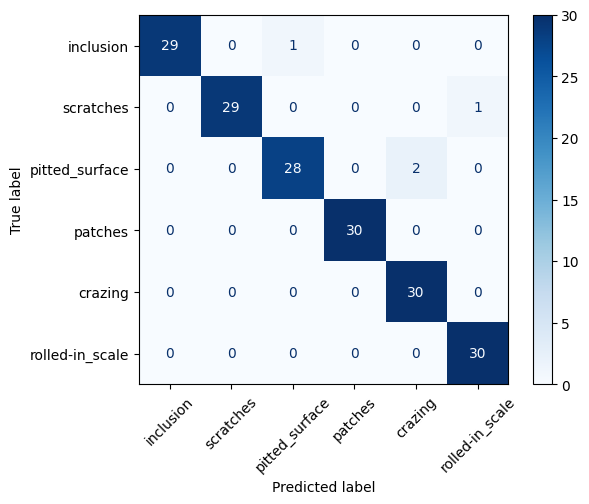

In [61]:
ConfusionMatrixDisplay.from_predictions(
    y_true,
    transfer_predictions,
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues"
)

plt.show()

Transfer Learning performed significantly better than the CNN we built from scratch. i will look at the 4 images the model predicted wrong

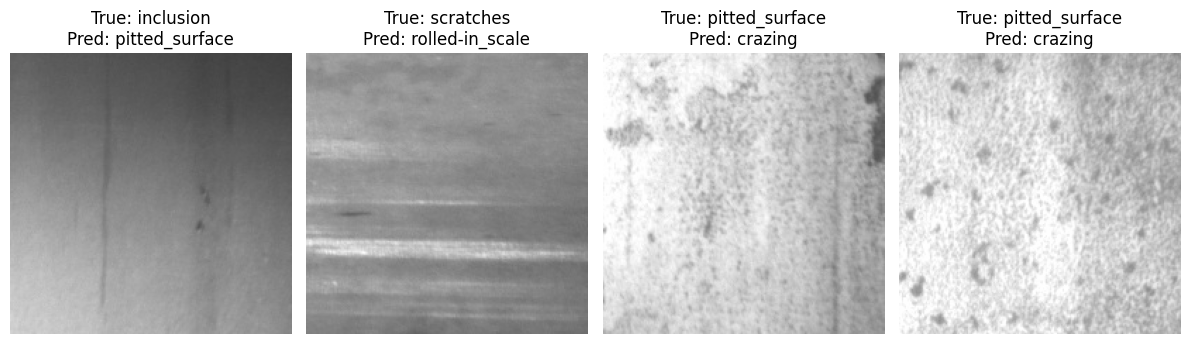

In [62]:
wrong_indices = np.where(
    y_true != transfer_predictions
)[0]

plt.figure(figsize=(12, 4))

for i, idx in enumerate(wrong_indices):
    image = plt.imread(val_paths[idx])

    plt.subplot(1, len(wrong_indices), i + 1)
    plt.imshow(image, cmap="gray")

    plt.title(
        f"True: {class_names[y_true[idx]]}\n"
        f"Pred: {class_names[transfer_predictions[idx]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

We achieved 97.78% Validation Accuracy, with only four incorrect predictions. Fine-Tuning might improve the results further, but it could also cause the model to overfit our specific training examples.

Since the model achieved very high accuracy in the first epoch, we should verify that there are no identical images across the datasets.
We will use SHA-256 to check for exact duplicates:

## Test Data Leakage

In [63]:
import hashlib

def image_hash(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

train_hashes = set(map(image_hash, train_paths))
val_hashes = set(map(image_hash, val_paths))
test_hashes = set(map(image_hash, test_paths))

print("Train-Val duplicates:", len(train_hashes & val_hashes))
print("Train-Test duplicates:", len(train_hashes & test_hashes))
print("Val-Test duplicates:", len(val_hashes & test_hashes))

Train-Val duplicates: 0
Train-Test duplicates: 0
Val-Test duplicates: 0


no data leakeage

## Final Evaluation on the Test Set

In [64]:
best_transfer_model = keras.models.load_model(
    "/content/drive/MyDrive/steel_defect_transfer.keras"
)

test_loss, test_accuracy = best_transfer_model.evaluate(test_dataset)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.9889 - loss: 0.0425
Test Accuracy: 0.9889
Test Loss: 0.0425


6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 351ms/step
                 precision    recall  f1-score   support

      inclusion       0.97      1.00      0.98        30
      scratches       1.00      1.00      1.00        30
 pitted_surface       1.00      0.93      0.97        30
        patches       1.00      1.00      1.00        30
        crazing       1.00      1.00      1.00        30
rolled-in_scale       0.97      1.00      0.98        30

       accuracy                           0.99       180
      macro avg       0.99      0.99      0.99       180
   weighted avg       0.99      0.99      0.99       180



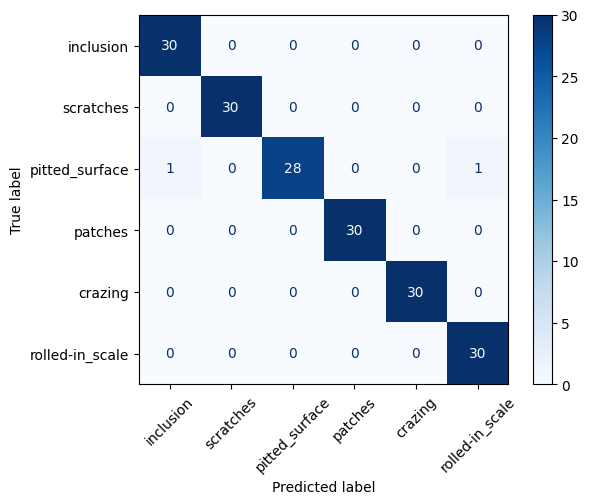

In [65]:
test_probabilities = best_transfer_model.predict(test_dataset)
test_predictions = np.argmax(test_probabilities, axis=1)

y_test = np.concatenate([
    labels.numpy() for images, labels in test_dataset
])

print(classification_report(
    y_test,
    test_predictions,
    target_names=class_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues"
)

plt.show()

Our MobileNetV2 model achieved 98.89% Accuracy on the Test Set, correctly classifying 178 out of 180 images that were not used for training or model selection.

lets check 2 last errors in test

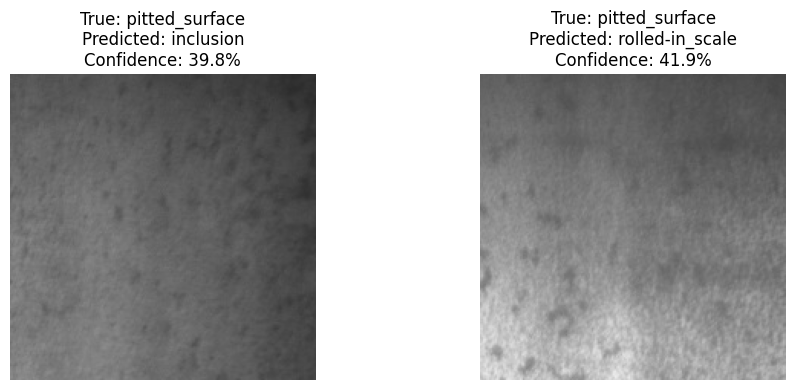

In [66]:
wrong_indices = np.where(y_test != test_predictions)[0]

plt.figure(figsize=(10, 4))

for i, idx in enumerate(wrong_indices):
    image = plt.imread(test_paths[idx])

    plt.subplot(1, len(wrong_indices), i + 1)
    plt.imshow(image, cmap="gray")

    plt.title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Predicted: {class_names[test_predictions[idx]]}\n"
        f"Confidence: {test_probabilities[idx].max():.1%}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

For both images, the model assigned only about 40% probability to the predicted class.
This is very different from a mistake where the model predicts the wrong class with 99% confidence.
This means the model did not strongly favor the incorrect classes. The probability assigned to pitted_surface may have been very close to that of the selected class.

## Grad-CAM
checks Which regions of the image did the model focus on when predicting a particular class

In our MobileNetV2 model, the last Convolutional layer is called Conv_1, followed by BatchNormalization and ReLU.

In [67]:
for layer in base_model.layers[-5:]:
    print(layer.name, layer.output.shape)

block_16_project (None, 7, 7, 320)
block_16_project_BN (None, 7, 7, 320)
Conv_1 (None, 7, 7, 1280)
Conv_1_bn (None, 7, 7, 1280)
out_relu (None, 7, 7, 1280)


In [68]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# המודל ששמרנו אחרי Transfer Learning
model = best_transfer_model

# MobileNetV2 שנמצאת בתוך המודל המלא
base = next(
    layer for layer in model.layers
    if isinstance(layer, keras.Model)
    and "mobilenetv2" in layer.name
)

# מודל שמחזיר את מפות המאפיינים האחרונות
feature_extractor = keras.Model(
    inputs=base.input,
    outputs=base.get_layer("out_relu").output
)

def make_gradcam_heatmap(image_batch):
    # אותו preprocessing שבו השתמשנו באימון
    x = model.layers[1](image_batch, training=False)
    x = model.layers[2](x)

    with tf.GradientTape() as tape:
        feature_maps = feature_extractor(x, training=False)

        # שכבות הסיווג שלנו
        pooled = model.layers[-2](feature_maps)
        predictions = model.layers[-1](pooled)

        predicted_class = tf.argmax(predictions[0])
        class_score = tf.gather(predictions[0], predicted_class)

    # השפעת מפות המאפיינים על התחזית
    gradients = tape.gradient(class_score, feature_maps)

    # ממוצע הגרדיאנטים לכל ערוץ
    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

    # שילוב מפות המאפיינים למפת חום אחת
    heatmap = tf.reduce_sum(
        feature_maps[0] * weights,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()

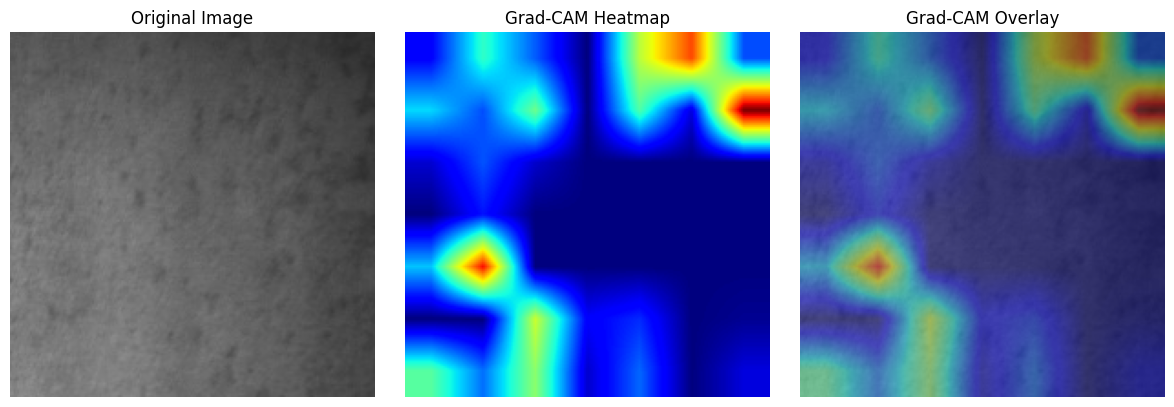

In [69]:
idx = wrong_indices[0]

image = load_and_preprocess_image(test_paths[idx])
image_batch = tf.expand_dims(image, axis=0)

heatmap = make_gradcam_heatmap(image_batch)

# הגדלת מפת החום מ-7x7 ל-200x200
heatmap_resized = tf.image.resize(
    heatmap[..., tf.newaxis],
    (200, 200)
).numpy().squeeze()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image.numpy())
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image.numpy())
plt.imshow(heatmap_resized, cmap="jet", alpha=0.45)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

First, some of the highlighted regions are near the edges of the image. The model may be influenced by texture features in these areas, but image boundaries or internal network processing could also play a role. We cannot determine the exact cause of the error from this alone.

Second, the heatmap appears relatively blurry. This is expected because we are upscaling a 7×7 feature map to 200×200. Therefore, Grad-CAM provides a coarse explanation rather than the precise location of each defect.

Let's compare it with an image that the model classified correctly.

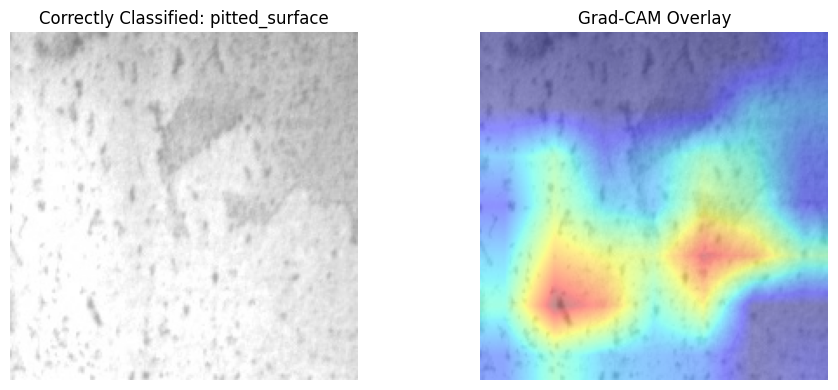

In [70]:
correct_indices = np.where(
    (y_test == test_predictions) &
    (y_test == class_to_index["pitted_surface"])
)[0]

idx = correct_indices[0]

image = load_and_preprocess_image(test_paths[idx])
image_batch = tf.expand_dims(image, axis=0)

heatmap = make_gradcam_heatmap(image_batch)

heatmap_resized = tf.image.resize(
    heatmap[..., tf.newaxis],
    (200, 200)
).numpy().squeeze()

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image.numpy())
plt.title("Correctly Classified: pitted_surface")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image.numpy())
plt.imshow(heatmap_resized, cmap="jet", alpha=0.45)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In the image correctly classified as pitted_surface, the highlighted regions (red and yellow) are mainly concentrated in the lower and central parts of the image.

These areas contain uneven textures with dark marks, consistent with the appearance of surface defects.

In contrast, in the previous image incorrectly classified as inclusion, the highlighted regions were more scattered, including near the image boundaries.

Conclusion: The model focuses on different regions when making predictions, but two examples are not enough to determine whether it consistently learns to focus on the correct defects.

## Conclusion

| Stage | Result |
|---|---|
| Basic CNN | Validation Accuracy: 76.67% |
| Deeper CNN + Augmentation | Validation Accuracy: 83.33% |
| MobileNetV2 + Transfer Learning | Validation Accuracy: 97.78% |
| Final Evaluation on Test Set | **Test Accuracy: 98.89%** |
| Explainability | Implemented Grad-CAM |